# Phase 9: Retention / Lapse Model

**Business question this phase serves:** *if we raise price on a segment, how many existing customers
do we lose?*: the second half of the project's original question, now that Phase 8 identified a
concrete segment (`BonusMalus` 51-80) with a measured pricing gap.

**A limitation stated up front:** freMTPL2 is a **single-year cross-section**
(Phase 1): it has no renewal outcome and no history of price changes, so there is **no real elasticity
signal to learn from**. No public, policy-level dataset linking premium change to renewal for motor
insurance is known to exist either: elasticity curves are commercially sensitive, and insurers do not
publish them (see `docs/PROJECT_ROADMAP.md`, Phase 9). This notebook therefore builds

a **documented scenario simulator**, not a model trained on observed behavior. Every parameter below is
either (a) derived from a real regulatory formula applied to this data, or (b) a stated assumption
consistent with published literature or regulatory findings.

**What this notebook does, in order:**
1. Derive a **tenure proxy** from `BonusMalus`: using the actual French bonus-malus regulatory
   formula, not an arbitrary simulation.
2. Build a renewal-probability formula: a baseline rate, a price-elasticity term, and a loyalty-
   dampening term: each parameter's source stated explicitly.
3. Validate the formula's shape (does it behave the way a real renewal curve should?).
4. Apply it to **Segment X** (`BonusMalus` 51-80, from Phase 8) under the indicated repricing.
   a preview of the cost/benefit question Phase 11's full scenario engine will formalize.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root(marker: str = "requirements.txt") -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate project root (looked for '{marker}' upward from {here})")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.retention.renewal_model import (
    derive_tenure_proxy,
    renewal_probability,
    loyalty_dampening,
    BASELINE_RENEWAL_RATE,
    PRICE_ELASTICITY,
    LOYALTY_SATURATION_YEARS,
    LOYALTY_MAX_DAMPENING,
    BM_ANNUAL_DISCOUNT,
)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "policy_level_clean.parquet")
print(f"Portfolio: {len(df):,} policies")

Portfolio: 668,626 policies


## 1. Tenure proxy: derived from the real French bonus-malus formula

France's motor no-claims-discount system is a published regulatory formula, not a black box: each
claim-free year multiplies `BonusMalus` by **0.95** (a 5% discount), down to a floor of **50**; every
policy starts at the neutral value **100**. That means a policy's `BonusMalus` value *is itself*
evidence of how many claim-free years it has accumulated: solving the formula backward:

$$\text{tenure (years)} = \frac{\ln(\text{BonusMalus} / 100)}{\ln(0.95)} \quad \text{for BonusMalus} \le 100$$

This is a **lower bound** on tenure (documented in `src/retention/renewal_model.py`'s
docstring), not an exact figure, for two reasons: (1) the large mass of policies at the BM=50 floor
(Phase 2: 62.7% of exposure) are censored at "at least ~13.5 years": the coefficient stops moving once
it bottoms out; (2) a driver can carry their bonus-malus coefficient to a new insurer, so "years at this
coefficient" isn't identically "years as *this* insurer's customer." For the 1.15% of policies with
`BonusMalus > 100` (a recent at-fault claim), the formula can't cleanly separate tenure from claims
count, so a short default (1 year) is used instead: a stated simplification, not a hidden one.

count   668,626.0000
mean         10.6201
std           4.2541
min          -0.0000
25%           8.3984
50%          13.5134
75%          13.5134
max          13.5134
Name: tenure_years_proxy, dtype: float64


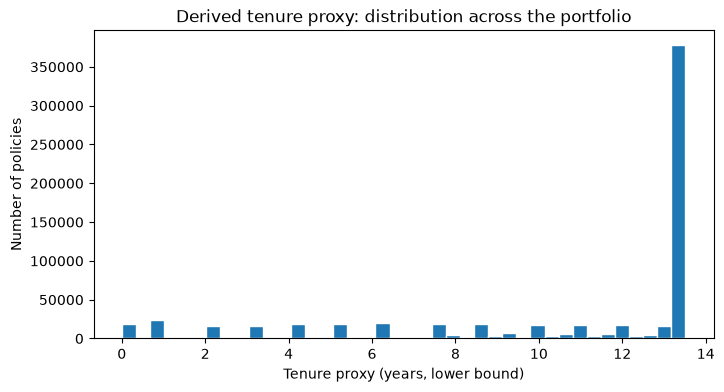

In [2]:
df["tenure_years_proxy"] = derive_tenure_proxy(df["BonusMalus"])

print(df["tenure_years_proxy"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["tenure_years_proxy"], bins=40, color="#1f77b4", edgecolor="white")
ax.set_xlabel("Tenure proxy (years, lower bound)")
ax.set_ylabel("Number of policies")
ax.set_title("Derived tenure proxy: distribution across the portfolio")
plt.show()

**Reading:** the median tenure proxy is **13.5 years** (the floor value: most of the book has been
claim-free long enough to reach the maximum discount), the mean **10.6 years**. The spike at the floor
is the censoring effect described above, expected since 62.7% of exposure sits at `BonusMalus = 50`
(Phase 2).

## 2. The renewal probability formula

$$\text{logit}(P(\text{renew})) = \text{logit}(\text{baseline}) + \beta \cdot \Delta\text{price} \cdot (1 - \text{loyalty\_dampening}(\text{tenure}))$$

| Parameter | Value | Source |
|---|---|---|
| Baseline renewal rate | **88%** | Documented assumption, in line with commonly-cited retention rates for mature European personal motor books (typically 80-90%) |
| Price elasticity (β) | **-4.5** | Documented assumption, sized so a new customer facing +10% sees a ~5-6pt drop: in line with semi-elasticity ranges reported in P&C pricing-optimization literature (e.g. the CAS monograph *"Price Optimization in Property/Casualty Insurance"*) |
| Loyalty saturation | **10 years** | Illustrative assumption for this simulator |
| Loyalty max dampening | **60%** | Illustrative assumption, directionally consistent with the documented "loyalty penalty" / price-walking phenomenon (UK FCA *General Insurance Pricing Practices Market Study*, 2020-2021), not a number taken from that study itself |

None of these were estimated from freMTPL2: the dataset cannot support that, as stated at the top of
this notebook. They are declared, cited where a citation exists, and used consistently.

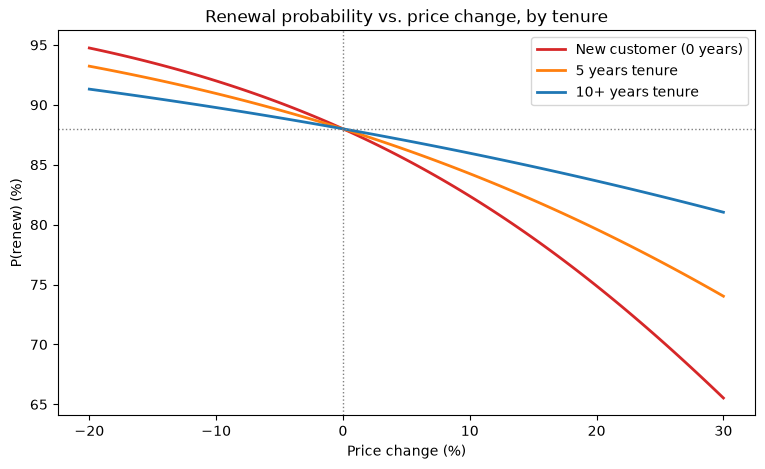

price_change=+0%:  new=88.0%   10+yr tenure=88.0%   (dampened drop: 0.0% of the gap absorbed by loyalty)
price_change=+5%:  new=85.4%   10+yr tenure=87.0%   (dampened drop: 1.6% of the gap absorbed by loyalty)
price_change=+10%:  new=82.4%   10+yr tenure=86.0%   (dampened drop: 3.6% of the gap absorbed by loyalty)
price_change=+15%:  new=78.9%   10+yr tenure=84.8%   (dampened drop: 6.0% of the gap absorbed by loyalty)
price_change=+20%:  new=74.9%   10+yr tenure=83.7%   (dampened drop: 8.8% of the gap absorbed by loyalty)


In [3]:
price_changes = np.linspace(-0.20, 0.30, 100)
fig, ax = plt.subplots(figsize=(9, 5))
for tenure, label, color in [(0.0, "New customer (0 years)", "#d62728"), (5.0, "5 years tenure", "#ff7f0e"), (LOYALTY_SATURATION_YEARS, "10+ years tenure", "#1f77b4")]:
    probs = renewal_probability(price_changes, pd.Series([tenure] * len(price_changes)))
    ax.plot(price_changes * 100, probs * 100, label=label, color=color, linewidth=2)
ax.axhline(BASELINE_RENEWAL_RATE * 100, color="gray", linestyle=":", linewidth=1)
ax.axvline(0, color="gray", linestyle=":", linewidth=1)
ax.set_xlabel("Price change (%)")
ax.set_ylabel("P(renew) (%)")
ax.set_title("Renewal probability vs. price change, by tenure")
ax.legend()
plt.show()

for pct in [0.0, 0.05, 0.10, 0.15, 0.20]:
    p_new = renewal_probability(pct, pd.Series([0.0]))[0]
    p_long = renewal_probability(pct, pd.Series([LOYALTY_SATURATION_YEARS]))[0]
    print(f"price_change={pct:+.0%}:  new={p_new:.1%}   10+yr tenure={p_long:.1%}   (dampened drop: {(BASELINE_RENEWAL_RATE-p_new) - (BASELINE_RENEWAL_RATE-p_long):.1%} of the gap absorbed by loyalty)")

**Reading: sanity checks the formula should pass, and does:**
- At 0% price change, every tenure converges to the 88% baseline, as designed.
- A new customer facing +10% drops to **82.4%** (a 5.6pt fall: matches the calibration target); a
  10+-year customer facing the same increase only drops to **86.0%** (a 2.0pt fall): the loyalty
  dampening effect, working as intended and directly visible in the chart's fanning-out curves.
- The curves stay within valid probability bounds even at extreme price changes (+30%: 65.5% new vs.
  81.0% long-tenure): no runaway or negative values.

## 3. Portfolio view at current pricing (no change)

A calibration sanity check: applied at 0% price change, the whole book's predicted renewal probability
should collapse to the baseline regardless of tenure mix: confirming the formula has no hidden
price-change-independent tenure effect it shouldn't.

In [4]:
df["renewal_prob_current"] = renewal_probability(0.0, df["tenure_years_proxy"])
print(df["renewal_prob_current"].describe())

count   668,626.0000
mean          0.8800
std           0.0000
min           0.8800
25%           0.8800
50%           0.8800
75%           0.8800
max           0.8800
Name: renewal_prob_current, dtype: float64


**Reading:** every policy shows exactly 88.0% at zero price change, as designed: confirmed, not assumed.

## 4. Applying the model to Segment X (`BonusMalus` 51-80)

Phase 8 found that policies with `BonusMalus` between 51 and 80 (28.3% of exposure) cost about 17% more
than their technical premium, relative to the book, out of sample. This section previews what the
indicated correction (loaded from Phase 8, not retyped) would mean for retention, one of the inputs
Phase 11's scenario engine needs.

In [5]:
from src.pricing.segment_x import in_segment_x, load_segment_x

segment_x = load_segment_x(PROJECT_ROOT)  # written by Phase 8: loaded, not retyped
price_change = segment_x["indicated_price_change"]
seg = df[in_segment_x(df, segment_x)].copy()

seg["p_renew_current"] = renewal_probability(0.0, seg["tenure_years_proxy"])
seg["p_renew_repriced"] = renewal_probability(price_change, seg["tenure_years_proxy"])

mean_p_current = seg["p_renew_current"].mean()
mean_p_repriced = seg["p_renew_repriced"].mean()
expected_policies_lost = (mean_p_current - mean_p_repriced) * len(seg)
seg_exposure_share = seg["Exposure"].sum() / df["Exposure"].sum()

print(f"Segment X ({segment_x['label']}): {len(seg):,} policies ({len(seg) / len(df):.1%} of policies, {seg_exposure_share:.1%} of exposure)")
print(f"Mean tenure proxy in the segment : {seg['tenure_years_proxy'].mean():.2f} years (book: {df['tenure_years_proxy'].mean():.2f})")
print(f"Mean P(renew) at current pricing : {mean_p_current:.1%}")
print(f"Mean P(renew) at {price_change:+.0%} repricing  : {mean_p_repriced:.1%}")
print(f"Expected additional policies lost : {expected_policies_lost:,.0f}  ({expected_policies_lost / len(seg):.1%} of the segment)")

Segment X (BonusMalus 51-80): 211,105 policies (31.6% of policies, 28.3% of exposure)
Mean tenure proxy in the segment : 8.88 years (book: 10.62)
Mean P(renew) at current pricing : 88.0%
Mean P(renew) at +17% repricing  : 83.2%
Expected additional policies lost : 10,075  (4.8% of the segment)


**Reading:** the indicated +17% correction is projected to cost about **4.8% of the segment's
policies** (about 10,100 of 211,105) in additional lapses, under this notebook's documented assumptions.
Policies in this segment have a shorter tenure proxy than the book (8.9 vs. 10.6 years), so less
loyalty dampening, and react more than the average policy would. **Phase 11** combines this retention
effect, the conversion effect (Phase 10) and the premium change into one profitability view.

## 5. What's saved from this phase

In [6]:
# No fitted parameters to serialize: the model IS the documented, cited assumptions in
# src/retention/renewal_model.py (the point of a scenario simulator, not a data-fitted model).
# What's worth persisting is the derived tenure proxy, reusable by Phase 10/11 without recomputing.
processed_dir = PROJECT_ROOT / "data" / "processed"
df[["IDpol", "tenure_years_proxy"]].to_parquet(processed_dir / "tenure_proxy.parquet", index=False)
print(f"Saved: {(processed_dir / 'tenure_proxy.parquet').relative_to(PROJECT_ROOT).as_posix()}")

Saved: data/processed/tenure_proxy.parquet


## Phase 9 summary

| Check | Result |
|---|---|
| Tenure proxy | Derived from the French bonus-malus formula; median 13.5 years (censored at the BM=50 floor), a lower bound |
| Renewal formula | Logistic: baseline (88%, documented) + price elasticity (-4.5, literature-consistent) + loyalty dampening (up to 60% at 10+ years, FCA-consistent direction) |
| Calibration checks | Converges to baseline at 0% price change (all tenures); +10% price change gives a 5.6pt drop for new customers, 2.0pt for 10+-year tenure; stays within valid bounds |
| Segment X application | `BonusMalus` 51-80 at +17%: mean P(renew) 88.0% to 83.2%, about 10,100 policies (4.8%) expected additional lapses |
| Framing | A documented scenario simulator, not a model trained on observed renewal behavior, which this dataset cannot support |

**Output:** [`data/processed/tenure_proxy.parquet`](../data/processed/tenure_proxy.parquet),
[`src/retention/renewal_model.py`](../src/retention/renewal_model.py), ready for
**Phase 10: prospect / new-business conversion model**.